# 02 — Ablación de memoria recurrente

> Esta notebook pregunta si procesar 63 sesiones con una LSTM aporta algo frente a una red sin memoria que ve únicamente las variables disponibles en la sesión de decisión. Es una ablación exploratoria sobre XLE: entrenamiento 2018–2022 y validación 2023. No consulta 2024–2026 ni demuestra alpha.

## <b>Block 01 — Baseline causal y muestra</b>

> Se reproduce la política TSMOM de la notebook 01: momentum logarítmico de 126 sesiones, volatilidad EWMA con $\lambda=0.94$, objetivo anual de 12% y exposición máxima de 1. La decisión en $t$ se aplica al retorno de $t+1$.

In [1]:
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from torch import nn

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

START = pd.Timestamp('2018-01-02')
TRAIN_END = pd.Timestamp('2022-12-31')
VALIDATION_END = pd.Timestamp('2023-12-31')
MOMENTUM_HORIZON = 126
MOMENTUM_FEATURES = (21, 63, 126)
EWMA_LAMBDA = 0.94
EWMA_WARMUP = 20
TARGET_VOLATILITY = 0.12
MAX_EXPOSURE = 1.00
LOOKBACK = 63
ADJUSTMENT_LIMIT = 0.20
RESEARCH_COST_PER_TURNOVER = 0.0005  # 5 bps por unidad de turnover; supuesto de investigación.
EPOCHS = 80
LEARNING_RATE = 0.01

def find_repo_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'Momentum_systematic_strategies').is_dir():
            return candidate
    raise FileNotFoundError('No se encontró la raíz del repositorio.')

ROOT = find_repo_root()
GOLD_PATH = ROOT / 'Momentum_systematic_strategies' / 'data' / 'gold' / 'daily_series' / 'etf' / 'XLE.parquet'
assert GOLD_PATH.exists(), f'Falta Gold: {GOLD_PATH}'
print(f'PyTorch {torch.__version__} | Gold: {GOLD_PATH.relative_to(ROOT)}')

PyTorch 2.12.0+cpu | Gold: Momentum_systematic_strategies\data\gold\daily_series\etf\XLE.parquet


In [2]:
gold = (
    pl.read_parquet(GOLD_PATH)
    .select('session_date', 'adjusted_close')
    .sort('session_date')
    .filter((pl.col('session_date') >= START.date()) & (pl.col('session_date') <= VALIDATION_END.date()))
)

frame = pd.DataFrame(gold.to_dict(as_series=False)).rename(columns={'session_date': 'decision_date'})
frame['decision_date'] = pd.to_datetime(frame['decision_date'])
frame['ret_1d'] = frame['adjusted_close'].pct_change()
for horizon in MOMENTUM_FEATURES:
    frame[f'mom_{horizon}'] = np.log(frame['adjusted_close'] / frame['adjusted_close'].shift(horizon))

returns = frame['ret_1d'].to_numpy(dtype=float)
variance = np.full(len(frame), np.nan)
first_valid = np.flatnonzero(np.isfinite(returns))[0]
initial_index = first_valid + EWMA_WARMUP - 1
variance[initial_index] = np.mean(returns[first_valid : initial_index + 1] ** 2)
for index in range(initial_index + 1, len(frame)):
    variance[index] = EWMA_LAMBDA * variance[index - 1] + (1 - EWMA_LAMBDA) * returns[index] ** 2

frame['ewma_vol_annual'] = np.sqrt(variance) * math.sqrt(252)
frame['baseline_position'] = np.where(
    frame['mom_126'] > 0,
    np.minimum(MAX_EXPOSURE, TARGET_VOLATILITY / frame['ewma_vol_annual']),
    0.0,
)
frame['return_date'] = frame['decision_date'].shift(-1)
frame['next_return'] = frame['ret_1d'].shift(-1)

feature_columns = ['ret_1d', 'mom_21', 'mom_63', 'mom_126', 'ewma_vol_annual']
frame['sequence_ready'] = frame[feature_columns].notna().all(axis=1).astype(int).rolling(LOOKBACK).sum().eq(LOOKBACK)
frame['_row'] = np.arange(len(frame))
sample = frame.loc[frame['sequence_ready'] & frame['next_return'].notna()].copy().reset_index(drop=True)

assert (sample['return_date'] > sample['decision_date']).all()
assert sample['baseline_position'].between(0, 1).all()
print(f'Muestra causal: {sample.decision_date.min():%Y-%m-%d} → {sample.return_date.max():%Y-%m-%d}; {len(sample):,} decisiones')

Muestra causal: 2018-10-01 → 2023-12-29; 1,320 decisiones


## <b>Block 02 — Modelos y división temporal</b>

> La LSTM usa la ventana causal de 63 sesiones de la notebook 01. La red feedforward observa solo las cinco variables normalizadas de la fecha $t$. El control constante aprende un único desplazamiento de exposición, sin variables. La normalización se ajusta solo con entrenamiento.

In [3]:
train_mask = sample['return_date'] <= TRAIN_END
validation_mask = (sample['return_date'] > TRAIN_END) & (sample['return_date'] <= VALIDATION_END)
train_idx = np.flatnonzero(train_mask.to_numpy())
validation_idx = np.flatnonzero(validation_mask.to_numpy())
assert sample.loc[train_idx, 'return_date'].max() <= TRAIN_END
assert sample.loc[validation_idx, 'return_date'].min() > TRAIN_END

train_rows = sample.loc[train_idx, '_row'].to_numpy()
raw_features = frame[feature_columns].to_numpy(dtype=np.float32)
feature_mean = raw_features[train_rows].mean(axis=0)
feature_std = np.maximum(raw_features[train_rows].std(axis=0), 1e-8)
scaled_features = (raw_features - feature_mean) / feature_std

def sequences_for(indices):
    rows = sample.loc[indices, '_row'].to_numpy()
    return np.stack([scaled_features[row - LOOKBACK + 1 : row + 1] for row in rows]).astype(np.float32)

X_sequence = sequences_for(np.arange(len(sample)))
X_current = scaled_features[sample['_row'].to_numpy()].astype(np.float32)
assert X_sequence.shape[1:] == (LOOKBACK, len(feature_columns))
assert X_current.shape == (len(sample), len(feature_columns))
assert np.array_equal(X_sequence[:, -1, :], X_current)
assert sample.loc[validation_idx, 'decision_date'].iloc[0] < pd.Timestamp('2023-01-01')

X_sequence_tensor = torch.tensor(X_sequence)
X_current_tensor = torch.tensor(X_current)
baseline_tensor = torch.tensor(sample['baseline_position'].to_numpy(dtype=np.float32))
next_return_tensor = torch.tensor(sample['next_return'].to_numpy(dtype=np.float32))
print(f"Train: {sample.loc[train_idx, 'return_date'].min():%Y-%m-%d} → {sample.loc[train_idx, 'return_date'].max():%Y-%m-%d}; {len(train_idx):,} retornos")
print(f"Validación: {sample.loc[validation_idx, 'return_date'].min():%Y-%m-%d} → {sample.loc[validation_idx, 'return_date'].max():%Y-%m-%d}; {len(validation_idx):,} retornos")

Train: 2018-10-02 → 2022-12-30; 1,070 retornos
Validación: 2023-01-03 → 2023-12-29; 250 retornos


In [4]:
class AnchoredLSTM(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=8, num_layers=1, batch_first=True)
        self.residual = nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight)
        nn.init.zeros_(self.residual.bias)

    def forward(self, features):
        hidden, _ = self.lstm(features)
        return ADJUSTMENT_LIMIT * torch.tanh(self.residual(hidden[:, -1, :]).squeeze(-1))

class AnchoredFeedForward(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.hidden = nn.Linear(n_features, 8)
        self.residual = nn.Linear(8, 1)
        nn.init.zeros_(self.residual.weight)
        nn.init.zeros_(self.residual.bias)

    def forward(self, features):
        return ADJUSTMENT_LIMIT * torch.tanh(self.residual(torch.tanh(self.hidden(features))).squeeze(-1))

class ConstantCorrection(nn.Module):
    def __init__(self):
        super().__init__()
        self.raw_adjustment = nn.Parameter(torch.zeros(()))

    def forward(self, features):
        return ADJUSTMENT_LIMIT * torch.tanh(self.raw_adjustment).expand(features.shape[0])

def net_returns(position, next_return, previous_position):
    turnover = torch.cat(((position[:1] - previous_position).abs(), (position[1:] - position[:-1]).abs()))
    costs = RESEARCH_COST_PER_TURNOVER * turnover
    return position * next_return - costs, turnover, costs

# La LSTM se construye primero con la misma semilla y configuración de la notebook 01.
lstm = AnchoredLSTM(len(feature_columns))
feedforward = AnchoredFeedForward(len(feature_columns))
constant = ConstantCorrection()
for model, inputs in [(lstm, X_sequence_tensor), (feedforward, X_current_tensor), (constant, X_current_tensor)]:
    with torch.no_grad():
        assert np.array_equal(model(inputs).numpy(), np.zeros(len(sample), dtype=np.float32))
print('Los tres correctores comienzan con ajuste exactamente cero.')

Los tres correctores comienzan con ajuste exactamente cero.


## <b>Block 03 — Entrenamiento fijo</b>

> Cada corrector maximiza el mismo Sharpe neto de entrenamiento. El coste es $0.0005\,|w_t-w_{t-1}|$; es un supuesto fijo de investigación, no una tarifa de ejecución verificada. No se seleccionan semillas, hiperparámetros ni modelos según 2023.

In [5]:
train_t = torch.tensor(train_idx, dtype=torch.long)

def train_model(model, inputs):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    losses = []
    for _ in range(EPOCHS):
        optimizer.zero_grad()
        adjustment = model(inputs[train_t])
        position = torch.clamp(baseline_tensor[train_t] + adjustment, 0.0, 1.0)
        # El primer retorno se excluye para que el turnover compare dos posiciones del modelo.
        net, _, _ = net_returns(position[1:], next_return_tensor[train_t][1:], position[:1])
        sharpe = net.mean() / net.std(unbiased=False).clamp_min(1e-6) * math.sqrt(252)
        loss = -sharpe
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        losses.append(float(loss.detach()))
    return losses

lstm_loss = train_model(lstm, X_sequence_tensor)
feedforward_loss = train_model(feedforward, X_current_tensor)
constant_loss = train_model(constant, X_current_tensor)

pd.DataFrame({
    'corrector': ['LSTM 63 sesiones', 'feedforward actual', 'constante'],
    'Sharpe neto final de entrenamiento': [-lstm_loss[-1], -feedforward_loss[-1], -constant_loss[-1]],
}).round(3)

,corrector,Sharpe neto final de entrenamiento
0,LSTM 63 sesiones,1.059
1,feedforward actual,1.030
2,constante,0.299


## <b>Block 04 — Validación económica 2023</b>

> Las cuatro alternativas se evalúan en las mismas 250 fechas de retorno. La tabla distingue la suma aritmética diaria, útil para separar retorno bruto y costes, del retorno neto compuesto, que determina la evolución del NAV.

In [6]:
with torch.no_grad():
    lstm_adjustment = lstm(X_sequence_tensor).numpy()
    feedforward_adjustment = feedforward(X_current_tensor).numpy()
    constant_adjustment = constant(X_current_tensor).numpy()

positions_all = {
    'TSMOM baseline': sample['baseline_position'].to_numpy(),
    'Corrección constante': np.clip(sample['baseline_position'].to_numpy() + constant_adjustment, 0.0, 1.0),
    'Feedforward actual': np.clip(sample['baseline_position'].to_numpy() + feedforward_adjustment, 0.0, 1.0),
    'LSTM 63 sesiones': np.clip(sample['baseline_position'].to_numpy() + lstm_adjustment, 0.0, 1.0),
}
assert all(np.all((position >= 0) & (position <= 1)) for position in positions_all.values())

context_index = validation_idx[0] - 1
evaluation_index = np.r_[context_index, validation_idx]

def evaluate(position_all, label):
    positions = position_all[evaluation_index]
    realized = sample.loc[validation_idx, 'next_return'].to_numpy()
    turnover = np.abs(np.diff(positions))
    costs = RESEARCH_COST_PER_TURNOVER * turnover
    gross = positions[1:] * realized
    net = gross - costs
    nav = np.r_[1.0, np.cumprod(1 + net)]
    drawdown = nav / np.maximum.accumulate(nav) - 1
    daily_vol = net.std(ddof=0)
    return {
        'estrategia': label, 'gross': gross, 'costs': costs, 'net': net, 'nav': nav, 'turnover': turnover,
        'retorno bruto suma (%)': gross.sum() * 100,
        'costes suma (%)': costs.sum() * 100,
        'retorno neto suma (%)': net.sum() * 100,
        'retorno neto compuesto (%)': (nav[-1] - 1) * 100,
        'volatilidad anual (%)': daily_vol * math.sqrt(252) * 100,
        'Sharpe neto': net.mean() / max(daily_vol, 1e-8) * math.sqrt(252),
        'max drawdown (%)': drawdown.min() * 100,
        'exposición media (%)': positions[1:].mean() * 100,
        'turnover total': turnover.sum(),
    }

evaluations = [evaluate(position, label) for label, position in positions_all.items()]
metrics = pd.DataFrame([{key: value for key, value in result.items() if key not in {'gross', 'costs', 'net', 'nav', 'turnover'}} for result in evaluations])
assert len(evaluations[0]['net']) == len(validation_idx) == 250
assert np.allclose(evaluations[0]['nav'][0], 1.0)
metrics.round(3)

,estrategia,retorno bruto suma (%),costes suma (%),retorno neto suma (%),retorno neto compuesto (%),volatilidad anual (%),Sharpe neto,max drawdown (%),exposición media (%),turnover total
0,TSMOM baseline,-1.761,0.304,-2.064,-2.552,10.242,-0.203,-8.182,38.262,6.075
1,Corrección constante,-1.540,0.304,-1.843,-2.583,12.488,-0.149,-10.146,49.617,6.075
2,Feedforward actual,-1.816,0.319,-2.135,-2.340,6.854,-0.314,-5.984,26.354,6.379
3,LSTM 63 sesiones,-1.975,0.413,-2.388,-2.786,9.395,-0.256,-8.506,33.088,8.254


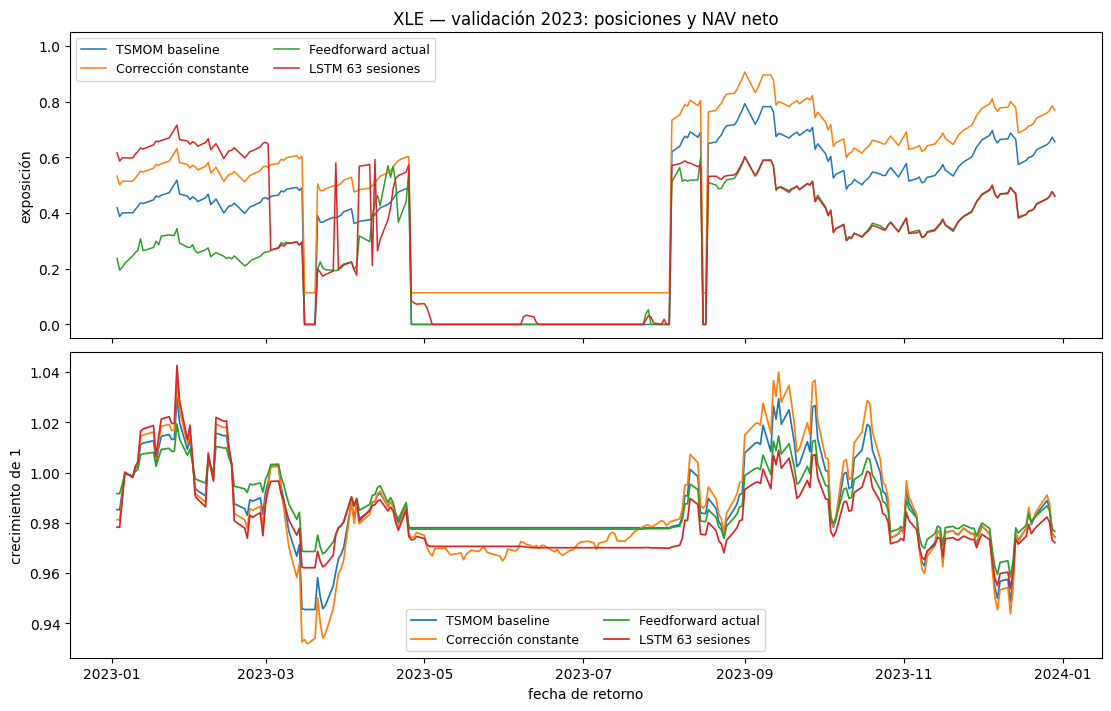

In [7]:
validation_dates = sample.loc[validation_idx, 'return_date']
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout='constrained')
for label, position in positions_all.items():
    axes[0].plot(validation_dates, position[validation_idx], label=label, lw=1.1)
axes[0].set_title('XLE — validación 2023: posiciones y NAV neto')
axes[0].set_ylabel('exposición')
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend(ncol=2, fontsize=9)

for result in evaluations:
    axes[1].plot(validation_dates, result['nav'][1:], label=result['estrategia'], lw=1.25)
axes[1].set_ylabel('crecimiento de 1')
axes[1].set_xlabel('fecha de retorno')
axes[1].legend(ncol=2, fontsize=9)
plt.show()

## <b>Conclusión</b>

- La comparación mantiene el mismo baseline causal, ventana de entrenamiento, periodo de validación, coste y límite de corrección.
- La red feedforward y el control constante permiten separar parcialmente una corrección basada en variables actuales y un simple desplazamiento de exposición de la memoria recurrente.
- Las diferencias de capacidad y arquitectura impiden atribuir cualquier brecha exclusivamente a memoria; 2023 es una única validación exploratoria.
- No se ha consultado 2024–2026, ni se ha seleccionado un modelo por esta comparación.

In [8]:
reference = metrics.set_index('estrategia')
for label in ['Corrección constante', 'Feedforward actual', 'LSTM 63 sesiones']:
    sharpe_delta = reference.loc[label, 'Sharpe neto'] - reference.loc['TSMOM baseline', 'Sharpe neto']
    compound_delta = reference.loc[label, 'retorno neto compuesto (%)'] - reference.loc['TSMOM baseline', 'retorno neto compuesto (%)']
    print(f'{label}: Δ Sharpe neto {sharpe_delta:+.3f}; Δ retorno neto compuesto {compound_delta:+.3f} pp.')

lstm_vs_ff = reference.loc['LSTM 63 sesiones', 'Sharpe neto'] - reference.loc['Feedforward actual', 'Sharpe neto']
print()
print(f'LSTM frente a feedforward: Δ Sharpe neto {lstm_vs_ff:+.3f}. Esta diferencia descriptiva no identifica por sí sola valor incremental de la memoria ni evidencia confirmatoria.')

Corrección constante: Δ Sharpe neto +0.054; Δ retorno neto compuesto -0.031 pp.
Feedforward actual: Δ Sharpe neto -0.111; Δ retorno neto compuesto +0.212 pp.
LSTM 63 sesiones: Δ Sharpe neto -0.053; Δ retorno neto compuesto -0.234 pp.

LSTM frente a feedforward: Δ Sharpe neto +0.058. Esta diferencia descriptiva no identifica por sí sola valor incremental de la memoria ni evidencia confirmatoria.
